<a href="https://colab.research.google.com/github/pccalegari/exemplos-CN/blob/main/Unidade5_Interpola%C3%A7%C3%A3o_CN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Aproximação de funções: Interpolação



Nesta unidade, vamos estudar métodos para aproximar funções e dados tabelados. Veremos duas maneiras de aproximar funções: o Método dos Mínimos Quadrados e a Interpolação polinomial. A seguir, apresentamos alguns exemplos de resolução em Python. Vamos utilizar as bibliotecas numpy e scipy.

**Interpolação Polinomial**

Vamos estudar métodos numéricos que permitem determinar um polinômio que passe por $n+1$ pontos conhecidos, denotados por $(x_0,y_0)$, $(x_1,y_1)$, $\ldots$, $(x_n,y_n)$, com $x_0\neq x_1\neq \ldots \neq x_n$. Em outras palavras, considere a tabela

$$\begin{array}{c|cccc}
x & x_0 & x_1 & \ldots & x_n \\
\hline
f(x) & f(x_0) & f(x_1) & \ldots & f(x_n) \\
\end{array}$$
sendo $f(x_i)=y_i$ para $i=0,1,\ldots, n$. Interpolar $x$ a tabela significa calcular $f(x)$, ou seja, incluir $(x,f(x))$ à tabela. Neste caso, vamos obter um polinômio aproximador $p(x)$ tal que $p(x_i) = y_i$, para $i=0,1,\ldots,n.$


Vamos estudar três formas de se obter um polinômio interpolador:

1.  Resolvendo um sistema linear.
2.  Fórmula de Lagrange.
3.  Forma de Newton.

O próximo resultado garante a existência e unicidade  do polinômio interpolador de uma tabela com $n+1$ pontos dados.

**Proposição:**

Dados $n+1$ pontos $(x_0,y_0),(x_1,y_1),\ldots,(x_n,y_n)$, com $x_0,x_1,\ldots,x_n$ distintos entre si, existe um único polinômio interpolador $p(x)$ de grau menor ou igual a $n$ que passa por esses pontos, ou seja, $p(x_i)=y_i$, para $i=0,1,\ldots,n$.

*demonstração:*

Seja $p(x)=a_0+a_1x+a_2x^2+\ldots+a_nx^n$ um polinômio de grau menor ou igual a $n$. Queremos determinar $a_0,a_1,\ldots,a_n$ de modo que: $p(x_i)=y_i$. Ou seja,
$$\begin{array}{cccccccccccccc}
p(x_0) & = & a_0 & + & a_1x_0 & + a_2x_0^2 & \ldots & + & a_nx_0^n = y_0\\
p(x_1) & = & a_0 & + & a_1x_1 & + a_2x_1^2 & \ldots & + & a_nx_1^n = y_1\\
\vdots \\
p(x_n) & = & a_0 & + & a_1x_n & + a_2x_n^2 & \ldots & + & a_nx_n^n = y_n\\
\end{array}$$

Na notação matricial,

$$\left(\begin{array}{ccccc}
1 & x_0 & x_0^2 & \ldots & x_0^n \\
1 & x_1 & x_1^2 & \ldots & x_1^n \\
\vdots \\
1 & x_n & x_n^2 & \ldots & x_n^n
\end{array}\right)\left(\begin{array}{c}
a_0\\
a_1\\
\vdots\\
a_n
\end{array}\right)=\left(\begin{array}{c}
y_0\\
y_1\\
\vdots\\
y_n
\end{array}\right)$$

Para mostrar a existência e unicidade do polinômio interpolador precisamos mostrar que o sistema linear tenha única solução.

Vamos considerar $n=1$ então temos o sistema linear:
$$\left(\begin{array}{cc}
1 & x_0 \\
1 & x_1
\end{array}\right)\left(\begin{array}{c}
a_0\\
a_1
\end{array}\right)=\left(\begin{array}{c}
y_0\\
y_1
\end{array}\right)$$

Como $x_0\neq x_1$ a matriz possui linhas linearmente independentes  e portanto o determinante é diferente de zero. Logo, a matriz é inversível e o sistema linear possui única solução. De forma análoga, usando o princípio da indução, verificamos para o caso geral, onde obtemos um sistema $(n+1)\times (n+1)$, já que $x_0\neq x_1\neq \ldots\neq x_n$.

*Exemplo 1:*

Dada a tabela de valores da função $f(x)=e^x$. Aproxime (interpole) $f(x)$ em $x=1.32$.

$$\begin{array}{c|ccc}
x & 1.3 & 1.4 & 1.5 \\
\hline
f(x) & 3.669 & 4.055 & 4.482 \\
\end{array}$$

*Exemplo 2:* Obtenha o polinômio interpolador da tabela e compare com a aproximação via MMQ.

$$\begin{array}{c|ccccc}
x_i & 0 & 0.25 & 0.5 & 0.75 & 1\\
\hline
y_i & 1 & 1.2840 & 1.6487 & 2.1170 & 2.7183 \\
\end{array}$$



2. **Forma de Lagrange:**

Seja $f$ uma função tabelada em $n+1$ pontos distintos $x_0,x_1,\ldots,x_n$ e sejam os polinômios de grau $n$:

$$L^n_i(x) = \dfrac{(x-x_0)(x-x_1)\ldots(x-x_{i-1})(x-x_{i+1})\ldots(x-x_n)}{(x_i-x_0)(x_i-x_1)\ldots(x_i-x_{i-1})(x_i-x_{i+1})\ldots(x_i-x_n)} = \prod_{j=0,j\neq i}^n\dfrac{x -x_j}{x_i-x_j},$$

denominados polinômios de Lagrange.

Note que, $L^n_i(x_i) = 1$ e $L^n_i(x_j)=0$ para $i\neq j$.

O polinômio interpolador de $f$ em relação aos pontos $(x_i,y_i)$ é dado por,

$$p(x)=L_0^n(x)f(x_0) + L_1^n(x)f(x_1) + \ldots + L_n^n(x)f(x_n)=\sum_{j=0}^n f(x_j)L_j^n(x)$$

A verificação que $p(x)$ é o polinômio interpolador segue diretamente da substituição dos pontos de interpolação. Por exemplo,

$$p(x_0) = f(x_0)L_0^n(x_0) + L_1^n(x)f(x_1) + \ldots + L_n^n(x)f(x_n) = f(x_0),$$
pois $L_0^n(x_0) = 1$ e $L_j^n(x_0)=0$, com $j=1,\ldots, n$.

Retornando ao exemplo (1):

Aproximar $f(x)=e^x$ em $x=1.32$, dados

$$\begin{array}{c|ccc}
x & 1.3 & 1.4 & 1.5 \\
\hline
f(x) & 3.669 & 4.055 & 4.482 \\
\end{array}$$

Utilizando os polinômios de Lagrange, temos:

$$\begin{array}{l}
L_0^2(x) = \dfrac{(x-1.4)(x-1.5)}{(1.3-1.4)(1.3-1.5)} = \dfrac{x^2-2.9x+2.1}{0.02}\\
L_1^2(x) = \dfrac{(x-1.3)(x-1.5)}{(1.4-1.3)(1.4-1.5)} = \dfrac{-x^2+2.8x-1.95}{0.01}\\
L_2^2(x) = \dfrac{(x-1.3)(x-1.4)}{(1.5-1.3)(1.5-1.4)} = \dfrac{x^2-2.7x+1.82}{0.02}\\
\end{array}$$

Portanto,
$$p(x) = 3.669L_0^2(x) + 4.055L_1^2(x) + 4.482L_2^2(x)$$

Assim, $p(1.32) = 3.669\times 0.72 + 4.055\times 0.36 + 4.482\times (-0.08) = 3.74292.$

**Exercício:**

Determine o polinômio que interpola $f(x)=1/x^2$ nos pontos $x_0=2$, $x_1=2.5$ e $x_2=4$. Avalie $f(3)$ e calcule o erro cometido.

**Teorema:**

Seja $[a,b]$ um intervalo que contém os pontos $x_, x_1,\ldots, x_n, (x_i\neq x_j)$ e $f(x)$ uma função com $n+1$ derivadas contínuas em $[a,b]$. O erro do polinômio interpolador de $f$ avaliado em $x\in [a,b]$ é dado por

$$E(x) = f(x) - p(x)  = \dfrac{f^{(n+1)}(\alpha)}{(n+1)!}{[(x-x_0)(x-x_1)\ldots(x-x_n)]},$$
com $\alpha\in[a,b]$. Apesar de $\alpha$ não ser determinado, a expressão acima é importante para que possamos fazer uma estimativa do erro cometido. Podemos limitar a derivada de ordem $n+1$ em $[a,b]$ por

$$|f^{(n+1)}(\alpha)|\le M = \max_{x\in[a,b]}|f^{(n+1)}(x)|,$$
e assim, obtemos:

$$|f(x) - p(x)|  = \dfrac{M}{(n+1)!}{|(x-x_0)(x-x_1)\ldots(x-x_n)|}.$$

A estimativa de erro, para o exercício anterior, onde $n+1=3$ e $f(x)=1/x^2$ é dada por:

$$|f(3)-p(3)|\le |(3-2)(3-2.5)(3-4)|\dfrac{0.75}{3!} = 0.0625,$$

pois $M = |f^{(3)}(2)| = 0.75$ e $f^{(3)} =-\dfrac{24}{x^5}.$



**Forma de Newton**

A forma de Newton utiliza uma fórmula de recorrência, ou seja, o polinômio de grau $n$ pode ser calculado a partir do polinômio de grau $n-1$. Vamos escrever o polinômio interpolador na forma:

$$
p_n(x) = c_0 + c_1(x - x_0) + c_2(x-x_0)(x-x_1) + \ldots + c_n(x-x_0)(x - x_1)\ldots(x-x_{n-1})
$$

As constantes $c_0,c_1,\ldots,c_n$ serão determinadas pelas condições de interpolação $p_n(x_i) = f(x_i)$, com $i=0,1,\ldots,n$. Fazendo $x = x_0$,  obtemos:

$$c_0 = f(x_0)$$

Para determinar $c_1$, usaremos $c_0=f(x_0)$ e reorganizamos a expressão acima, obtemos:

$$\dfrac{p_n(x) - f(x_0)}{x - x_0} = c_1 + c_2(x - x_1) + \ldots + c_n(x-x_1)\ldots(x - x_{n-1}).$$

Fazendo $x = x_1$, obtemos:

$$c_1 = \dfrac{f(x_1) - f(x_0)}{x_1-x_0}.$$

A ideia é continuar este processo para obter os demais coeficientes: $c_2,c_3\ldots,c_n$.

$\bullet$ Definição de Diferenças Divididas:

Seja $f[x_0] = f(x_0)$ e por recorrência definimos para qualquer $k$,
$f[x_0,x_1,x_k] = \dfrac{f[x_1,\ldots,x_k] - f[x_0,\ldots,x_{k-1}]}{x_k - x_0}$

Por exemplo,

$f[x_0] = f(x_0), f[x_0,x_1] = \dfrac{f(x_1)-f(x_0)}{x_1-x_0}$, $f[x_0,x_1,x_2]=\dfrac{f[x_1,x_2]-f[x_0,x_1]}{x_2-x_0}$


$$c_k = f[x_0,x_1,\ldots,x_k]$$

Assim, o polinômio interpolador na forma de Newton é dado por:

$$p_n(x) = f[x_0] + f[x_0,x_1](x - x_0) + f[x_0,x_1,x_2](x-x_0)(x-x_1) + \ldots + f[x_0,x_1,\ldots,x_n](x-x_0)(x-x_1)\ldots(x-x_{n-1})$$

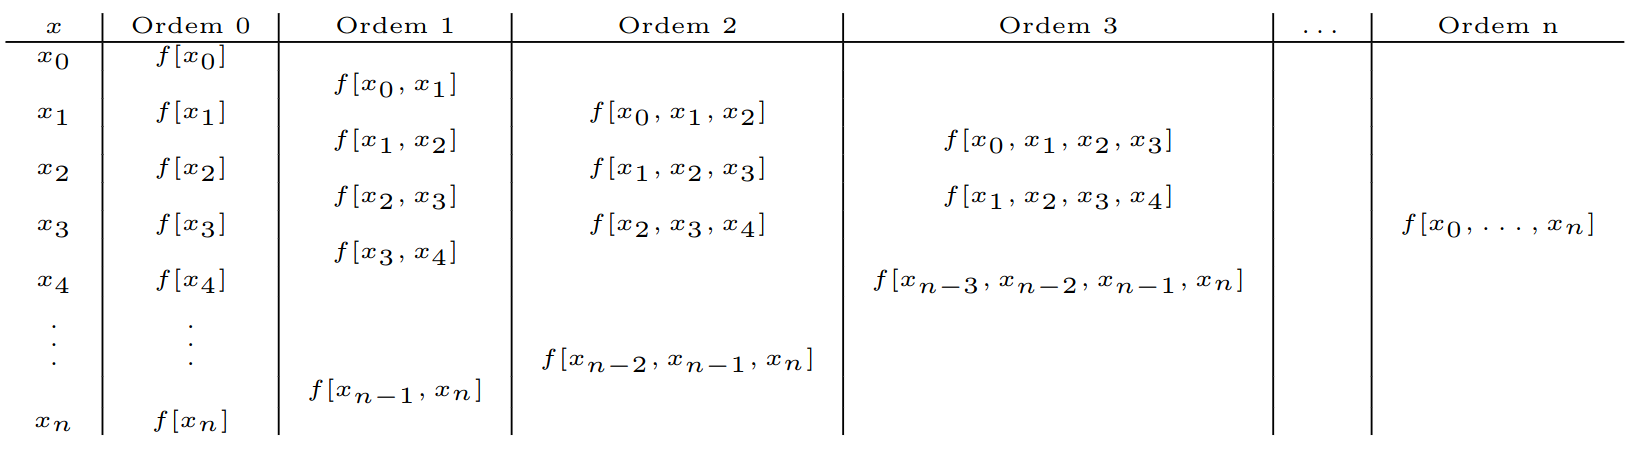

Por exemplo,

Uma dirença dividida de ordem 0, $f[x_0] = y_0,$ de ordem 1, $f[x_0,x_1] = \dfrac{f[x_1] - f[x_0]}{x_1-x_0}$, de ordem 2, $f[x_0,x_1,x_2] = \dfrac{f[x_1,x_2] - f[x_0,x_1]}{x_2 - x_0}, \ldots$ e de ordem n
$f[x_0,x_1,\ldots,x_n] = \dfrac{f[x_1,x_2,\ldots,x_n] - f[x_0,x_1,\ldots,x_{n-1}]}{x_n - x_0}$


**Algoritmo - Tabela de Diferenças Divididas**

1.   Dados $x_i$ e $f(x_i)$,  $n+1$ pontos.
2.   Para $i=0:n$
3.   $\hspace{1pc}$  $d_{i0}=f(x_i)$
4.   Para $k = 1:n$
5.   $\hspace{1pc}$ Para $i=0:n-k$
6.   $\hspace{2pc} d_{ik}=\dfrac{d_{i+1,k-1}-d_{i,k-1}}{x_{i+k}-x_i}$


O polinômio é dado por

$$p(x) = f[x_0]+f[x_0,x_1](x-x_0)+f[x_0,x_1,x_2](x-x_0)(x-x_1)+\ldots+f[x_0,x_1,\ldots,x_{n-1},x_n](x-x_0)(x-x_1)\ldots(x-x_{n-1}),$$

onde $f[x_0]=f(x_0)$ e para qualquer $k$, $$f[x_0,x_1,\ldots,x_k,x]=\dfrac{f[x_0,x_1,\ldots,x_{k-1},x]-f[x_0,x_1,\ldots,x_k]}{x-x_k}$$

**Exercício:** Implemente o método de Diferenças Divididas para obter o polinômio interpolador dos exemplos anteriores.






*Exemplo 3:*

Dada a tabela de valores
$$\begin{array}{c|ccccccc}
x & 1 & 2 & 3 & 4 & 5 & 6 & 7 & 8\\
\hline
f(x) & 0.5 & 0.6 & 0.9 & 0.8 & 1.2 & 1.5 & 1.7 & 2\\
\end{array}$$

Obtenha o polinômio que interpola os dados da tabela.

**Solução:**

Vamos utilizar a tabela de Diferenças Divididas para determinar o polinômio iterpolador. Como a tabela possui 8 pontos o grau do polinômio interpolador será 7.

$p(x) = c_0 + c_1(x - x_0) + c_2(x - x_0)(x - x_1) + \ldots + c_7(x - x_0)(x - x_1)\cdots (x - x_6)$

A tabela de Diferenças Divididas é dada por

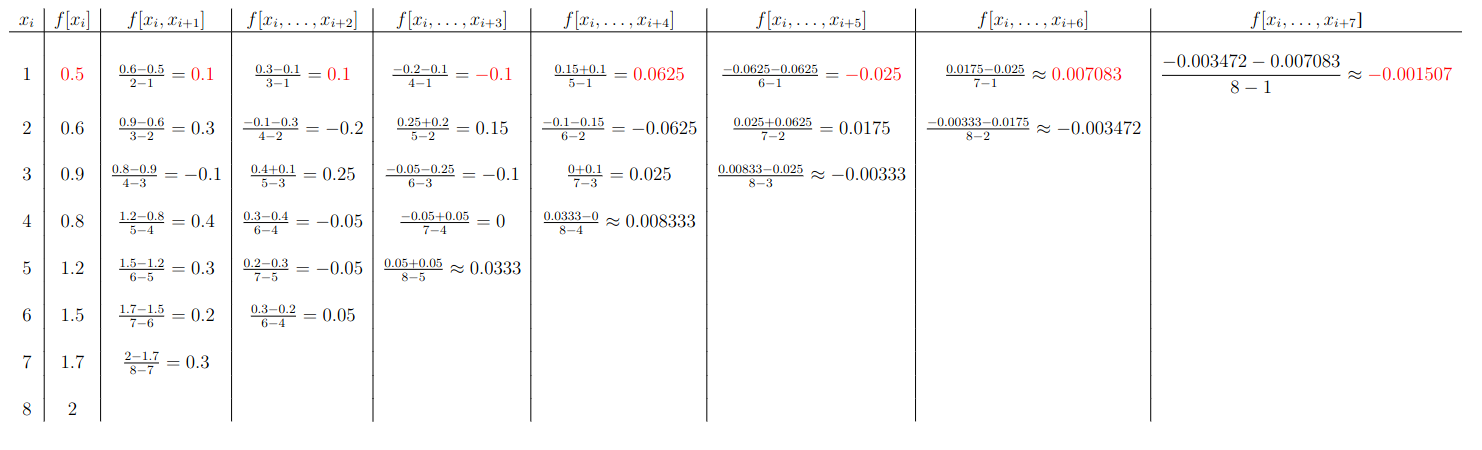

Portanto o polinômio interpolador na Forma de Newton é dado por,

$\begin{array}{rcl}
p(x) & = & 0.5 + 0.1(x - 1) + 0.1(x - 1)(x - 2) - 0.1(x-1)(x-2)(x-3) + 0.0625(x - 1)(x - 2)(x-3)(x-4) + \\
&  - & 0.025(x - 1)(x-2)(x-3)(x-4)(x-5) + 0.007083(x-1)(x-2)(x-3)(x-4)(x-5)(x-6) + \\
&  - & 0.001507(x-1)(x-2)(x-3)(x-4)(x-5)(x-6)(x-7)
\end{array}$

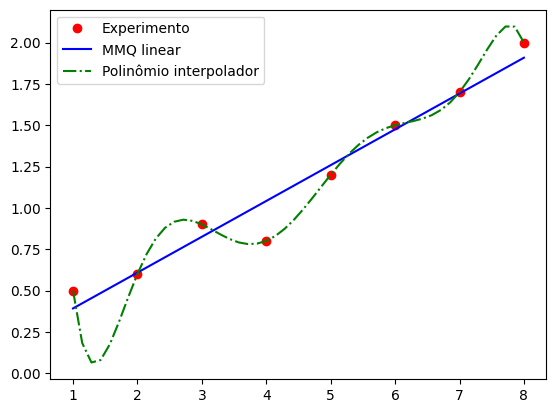

**Exercício:** Implementar a tabela de Diferenças Divididas de Newton e a avaliação do polinômio na forma de Newton.

In [ ]:
# Neste exemplo comparamos a aproximação via MMQ e Interpolação polinomial
import numpy as np
import matplotlib.pyplot as plt

def g(x,a):
  return a[0] + a[1]*x

def dif_div(x,y):

  return c

def p(x0, x, c):

  return px0

x = np.array([1,2,3,4,5,6,7,8])
y = np.array([0.5, 0.6, 0.9, 0.8, 1.2, 1.5, 1.7, 2])

n = len(x)
u = np.ones(n)
M = np.zeros((2,2))
b = np.zeros(2)

#sistema Normal
M[0][0] = np.dot(u,u)
M[0][1] = np.dot(u,x)
M[1][0] = M[0][1]
M[1][1] = np.dot(x,x)
b[0] = np.dot(u,y)
b[1] = np.dot(x,y)

#Regressao Linear
a = np.linalg.solve(M,b)

#Tabela de Diferenças Divididas
c = dif_div(x,y)
print(c)

xx = np.linspace(x[0],x[n-1],50)
plt.figure(1)
plt.plot(x,y,'ro',label='Experimento')
plt.plot(xx,g(xx,a),'b-', label = 'MMQ linear')
plt.plot(xx,p(xx, x, c),'g-.', label = 'Polinômio interpolador')
plt.legend()
plt.show()